<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#爬虫和数据整理分析输出的示例" data-toc-modified-id="爬虫和数据整理分析输出的示例-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>爬虫和数据整理分析输出的示例</a></span><ul class="toc-item"><li><span><a href="#爬虫示例，不能在cell直接运行，需要一个webreptile插件（自编写的）" data-toc-modified-id="爬虫示例，不能在cell直接运行，需要一个webreptile插件（自编写的）-1.1"><span class="toc-item-num">1.1&nbsp;&nbsp;</span>爬虫示例，不能在cell直接运行，需要一个webreptile插件（自编写的）</a></span></li><li><span><a href="#进行数据清洗" data-toc-modified-id="进行数据清洗-1.2"><span class="toc-item-num">1.2&nbsp;&nbsp;</span>进行数据清洗</a></span></li><li><span><a href="#数据整理" data-toc-modified-id="数据整理-1.3"><span class="toc-item-num">1.3&nbsp;&nbsp;</span>数据整理</a></span></li><li><span><a href="#岗位统计分析" data-toc-modified-id="岗位统计分析-1.4"><span class="toc-item-num">1.4&nbsp;&nbsp;</span>岗位统计分析</a></span></li><li><span><a href="#地区信息分析" data-toc-modified-id="地区信息分析-1.5"><span class="toc-item-num">1.5&nbsp;&nbsp;</span>地区信息分析</a></span></li><li><span><a href="#岗位薪酬分析" data-toc-modified-id="岗位薪酬分析-1.6"><span class="toc-item-num">1.6&nbsp;&nbsp;</span>岗位薪酬分析</a></span></li><li><span><a href="#地区薪酬分析" data-toc-modified-id="地区薪酬分析-1.7"><span class="toc-item-num">1.7&nbsp;&nbsp;</span>地区薪酬分析</a></span></li><li><span><a href="#tfidf算法" data-toc-modified-id="tfidf算法-1.8"><span class="toc-item-num">1.8&nbsp;&nbsp;</span>tfidf算法</a></span></li><li><span><a href="#textrank算法" data-toc-modified-id="textrank算法-1.9"><span class="toc-item-num">1.9&nbsp;&nbsp;</span>textrank算法</a></span></li><li><span><a href="#对岗位需求进行tfidf关键字提取" data-toc-modified-id="对岗位需求进行tfidf关键字提取-1.10"><span class="toc-item-num">1.10&nbsp;&nbsp;</span>对岗位需求进行tfidf关键字提取</a></span></li><li><span><a href="#对岗位需求进行textrank关键字提取" data-toc-modified-id="对岗位需求进行textrank关键字提取-1.11"><span class="toc-item-num">1.11&nbsp;&nbsp;</span>对岗位需求进行textrank关键字提取</a></span></li><li><span><a href="#对关键字进行云词图显示" data-toc-modified-id="对关键字进行云词图显示-1.12"><span class="toc-item-num">1.12&nbsp;&nbsp;</span>对关键字进行云词图显示</a></span></li></ul></li></ul></div>

# 爬虫和数据整理分析输出的示例

## 爬虫示例，不能在cell直接运行，需要一个webreptile插件（自编写的）

In [ ]:
#coding:utf-8
from  webreptile import Worm
import pandas as pd
import sys
import time
import urllib
start_time=time.time()
sp = Worm()
spider={}
search_job='物联网'
spider['phantomjs']=False
spider['delimiter']=','
spider['thread']=True
spider['thread_block']=False
spider['fields']={'main_css':'//div[@class="dw_table"]/div[@class="el"]',
                  'field_css':['.//span[@class="t2"]/a[@target="_blank"]/text()',
                                './/span[@class="t3"]/text()',
                                './/span[@class="t4"]/text()',
                                './/span[@class="t5"]/text()',
                                './/p[@class="t1 "]/span/a[@target="_blank"]/text()'],
                 'href_css':'.//a/@href','only_href':True,
                  'css':{'main_css':'//div[@class="bmsg job_msg inbox"]','field_css':['./text()']}}
fp=open(sys.argv[1],'a')
spider['file']=fp
# spider['file']=sys.argv[1]

str1=urllib.quote(search_job)
for i in range(1, 100):
    url1 = 'http://search.51job.com/list/000000,000000,0000,00,9,99,'+str1+',2,'
    url2 = '.html?lang=c&stype=1&postchannel=0000&workyear=99&cotype=99&degreefrom=99&jobterm=99&companysize=99&lonlat=0%2C0&radius=-1&ord_field=0&confirmdate=9&fromType=&dibiaoid=0&address=&line=&specialarea=00&from=&welfare='
    url = url1 + str(i) + url2
    spider['url']=url
    b_c=sp.begin_spider(spider)
end_time=time.time()
print '总耗时(秒）：'+`end_time-start_time`

## 进行数据清洗

In [26]:
%%time
%matplotlib inline
import pandas as pd
import re
import jieba.analyse as analyse
import numpy as np
import time
def min_pay(x):
    if '-' in x and '月' in x:
        tmp = x.split('-')

        if '千' in tmp[1]:
            return float(tmp[0]) * 1000
        else:
            return float(tmp[0]) * 10000
    else:
        t = re.findall(r"\d+\.?\d*", x)
        if '千' in x:

            return float(t[0]) * 1000
        else:
            return float(t[0]) * 10000

def max_pay(x):
    if '-' in x and '月' in x:
        tmp = x.split('-')
        t=re.findall(r"\d+\.?\d*", tmp[1])
        if '千' in tmp[1]:
            return float(t[0]) * 1000
        else:
            return float(t[0]) * 10000
    else:
        t = re.findall(r"\d+\.?\d*", x)
        if '千' in x:
            return float(t[0]) * 1000
        else:
            return float(t[0]) * 10000

def area(x):
    if '-' in x:
        tmp = x.split('-')
        return tmp[0]
    else:
        return x


filen1='wulianwang.csv'

df = pd.read_csv(filen1, delimiter=',',index_col=False, names=['company', 'area', 'pay', 'date', 'post', 'work','danwei'])
df = df.dropna()
df = df[df['pay'].str.contains('月')]
print (df)


                company    area         pay   date  \
0                  网易集团      广州    1.5-2万/月  03-05   
1        南京金固建设（集团）有限公司  南京-鼓楼区    0.4-1万/月  03-05   
2          杭州博彦信息技术有限公司  杭州-西湖区      4-6千/月  03-05   
3         南京雨花中兴信雅达培训中心  南京-栖霞区      6-8千/月  03-05   
4          重庆汶昌智能科技有限公司  重庆-渝北区      3-5千/月  03-05   
...                 ...     ...         ...    ...   
16172    天津荣联汇智智能科技有限公司  天津-北辰区      4-7千/月  01-26   
16173      北京汉能光伏技术有限公司    异地招聘    1.5-2千/月  02-11   
16175          深圳掌控网络公司  深圳-南山区  0.8-1.2万/月  01-23   
16176  成都迅网电信工程技术咨询有限公司  成都-高新区  0.8-1.2万/月  01-12   
16177      重庆光控兴渝置业有限公司  重庆-渝中区  0.7-1.5万/月  01-08   

                             post  \
0      资深嵌入式软件开发工程师（物联网开发方向）-网易严选   
1                          物联网工程师   
2              阿里-阿里云-渠道运营（物联网方向）   
3                         物联网方向讲师   
4                       智能物联网产品专员   
...                           ...   
16172                       电气工程师   
16173               大客户总监(029305)   
16175             

## 数据整理

In [27]:
df['minpay'] = df['pay'].apply(lambda x: min_pay(x))
df['maxpay'] = df['pay'].apply(lambda x: max_pay(x))

df['area'] = df['area'].apply(lambda x: area(x))
#     print df
df = df[df['maxpay'] > df['minpay']]
df['post'] = df['post'].str.upper()
print (df)

                company  area         pay   date                        post  \
0                  网易集团    广州    1.5-2万/月  03-05  资深嵌入式软件开发工程师（物联网开发方向）-网易严选   
1        南京金固建设（集团）有限公司    南京    0.4-1万/月  03-05                      物联网工程师   
2          杭州博彦信息技术有限公司    杭州      4-6千/月  03-05          阿里-阿里云-渠道运营（物联网方向）   
3         南京雨花中兴信雅达培训中心    南京      6-8千/月  03-05                     物联网方向讲师   
4          重庆汶昌智能科技有限公司    重庆      3-5千/月  03-05                   智能物联网产品专员   
...                 ...   ...         ...    ...                         ...   
16172    天津荣联汇智智能科技有限公司    天津      4-7千/月  01-26                       电气工程师   
16173      北京汉能光伏技术有限公司  异地招聘    1.5-2千/月  02-11               大客户总监(029305)   
16175          深圳掌控网络公司    深圳  0.8-1.2万/月  01-23                 .NET中级开发工程师   
16176  成都迅网电信工程技术咨询有限公司    成都  0.8-1.2万/月  01-12                       项目负责人   
16177      重庆光控兴渝置业有限公司    重庆  0.7-1.5万/月  01-08                        信息主管   

                                       

## 岗位统计分析

销售经理             303
嵌入式软件工程师         222
产品经理             173
销售工程师            132
JAVA开发工程师        113
                ... 
物流/车辆/运输调度         1
产品生产项目经理           1
软件部部门经理            1
硬件项目总监             1
ASP.NET 高级工程师      1
Name: post, Length: 7875, dtype: int64


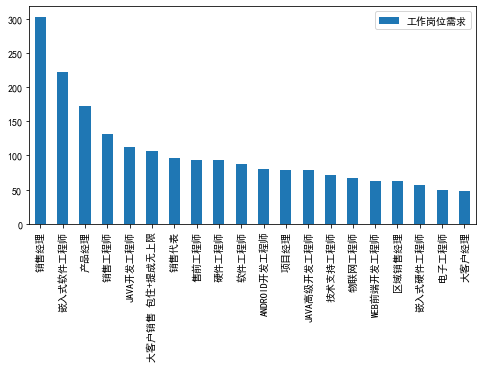

In [32]:
df_w = df['post'].value_counts()
print(df_w)
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.pylab as pylab
plt.rcParams['font.family'] = ['SimHei']
figure1 = plt.figure(2, figsize=(8, 4))
df_w.head(20).plot(kind='bar', label=u'工作岗位需求')
plt.legend()
plt.show()

## 地区信息分析

深圳      2290
上海      2047
广州      1321
异地招聘    1134
杭州       880
Name: area, dtype: int64


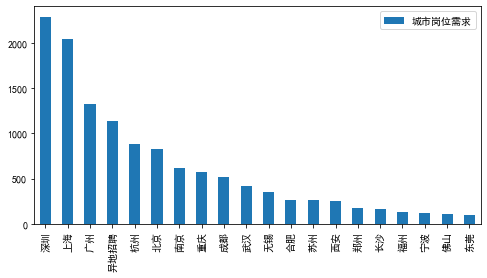

In [34]:

df_a = df['area'].value_counts()
print(df_a.head(5))
figure1 = plt.figure(2, figsize=(8, 4))
df_a.head(20).plot(kind='bar',  label=u'城市岗位需求')
plt.legend()
plt.show()

## 岗位薪酬分析

                        max           min
post                                     
销售经理           13267.326733   7821.782178
嵌入式软件工程师       15668.918919   9439.189189
产品经理           16433.526012  10257.225434
销售工程师          10616.666667   6125.000000
JAVA开发工程师      14513.274336   8787.610619
...                     ...           ...
物流/车辆/运输调度      6000.000000   5000.000000
产品生产项目经理       15000.000000  10000.000000
软件部部门经理        25000.000000  16000.000000
硬件项目总监         25000.000000  20000.000000
ASP.NET 高级工程师  15000.000000  10000.000000

[7875 rows x 2 columns]


<Figure size 576x432 with 0 Axes>

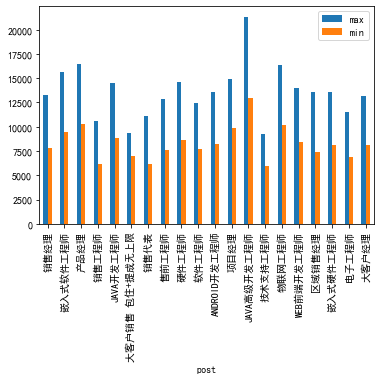

In [37]:
pay_l = []
for i in range(0, len(df_w.index)):
    pay_l.append([df_w.index[i], df[df['post'] == df_w.index[i]]['maxpay'].mean(),
                  df[df['post'] == df_w.index[i]]['minpay'].mean()])

df_pay = pd.DataFrame(pay_l, columns=['post', 'max', 'min'])
df_pay = df_pay.set_index('post')
figure1 = plt.figure(2, figsize=(8, 6))
print (df_pay)
df_pay.head(20).plot(kind='bar',  label=u'岗位薪酬')
plt.legend()
plt.show()

## 地区薪酬分析

               max           min
area                            
深圳    16447.336245  10059.912664
上海    16003.810454  10112.750366
广州    13503.860712   8161.922786
异地招聘  14757.671958   9069.223986
杭州    15928.181818   9945.454545
...            ...           ...
达州     6000.000000   4500.000000
张家界   10000.000000   4000.000000
常熟    20000.000000  10000.000000
清远    10000.000000   8000.000000
吉林省   15000.000000  10000.000000

[177 rows x 2 columns]


<Figure size 576x432 with 0 Axes>

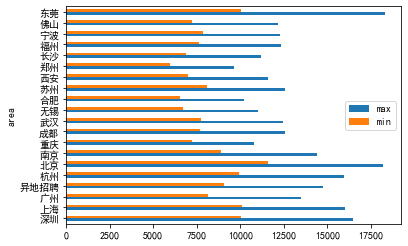

In [38]:

pay_a = []
for i in range(0, len(df_a.index)):
    pay_a.append([df_a.index[i], df[df['area'] == df_a.index[i]]['maxpay'].mean(),
                  df[df['area'] == df_a.index[i]]['minpay'].mean()])
df_areapay = pd.DataFrame(pay_a, columns=['area', 'max', 'min'])
df_areapay = df_areapay.set_index('area')
print(df_areapay)
figure1 = plt.figure(2, figsize=(8, 6))
df_areapay.head(20).plot(kind='barh', label=u'城市薪酬')
plt.legend()
plt.show()

## tfidf算法

In [41]:
from jieba import analyse
# 引入TF-IDF关键词抽取接口
tfidf = analyse.extract_tags

text = "1、负责物联网产品相关嵌入式软件设计、开发、调试及维护；\
2、负责物联网产品的蓝牙、WiFi、Zigbee、NB-IOT等模块的开发和维护工作；\
 3、编写相关软件设计文档及其它技术文档；Requirements\
 1、计算机、通信或相关专业本科及以上学历，五年以上相关行业工作经验；\
 2、精通嵌入式C/C++编程，熟悉多线程编程、进程和线程通信等；熟练使用lua、python等；具备良好的编码习惯；\
 3、熟悉单片机、ARM架构处理器，具备OS（FreeRTOS、嵌入式Linux等）开发经验，熟练使用Keil/IAR等开发环境；\
 4、熟悉TCP/IP网络协议栈，熟悉802.11协议，有BR/EDR、BLE、Zigbee等开发经验；有MQTT、COAP开发经验优先；\
 5.  熟悉UART、SPI、I2C、FLASH等基本外围驱动的开发；6. 工作踏实勤奋，责任心强，有较强的沟通能力及合作意识。"
 
# 基于TF-IDF算法进行关键词抽取
keywords = tfidf(text)
print ("关键字 by tfidf:")
# 输出抽取出的关键词
for keyword in keywords:
    print (keyword ,end="/")


keywords by tfidf:
线程/CPU/进程/调度/多线程/程序执行/每个/执行/堆栈/局部变量/单位/并发/分派/一个/共享/请求/最小/可以/允许/分配/

## textrank算法

In [ ]:
from jieba import analyse

# 引入textrank
textrank = analyse.textrank
text = "1、负责物联网产品相关嵌入式软件设计、开发、调试及维护；\
2、负责物联网产品的蓝牙、WiFi、Zigbee、NB-IOT等模块的开发和维护工作；\
 3、编写相关软件设计文档及其它技术文档；Requirements\
 1、计算机、通信或相关专业本科及以上学历，五年以上相关行业工作经验；\
 2、精通嵌入式C/C++编程，熟悉多线程编程、进程和线程通信等；熟练使用lua、python等；具备良好的编码习惯；\
 3、熟悉单片机、ARM架构处理器，具备OS（FreeRTOS、嵌入式Linux等）开发经验，熟练使用Keil/IAR等开发环境；\
 4、熟悉TCP/IP网络协议栈，熟悉802.11协议，有BR/EDR、BLE、Zigbee等开发经验；有MQTT、COAP开发经验优先；\
 5.  熟悉UART、SPI、I2C、FLASH等基本外围驱动的开发；6. 工作踏实勤奋，责任心强，有较强的沟通能力及合作意识。"
# 进行关键词抽取
keywords = textrank(text,topK=30)
print ("关键字 by tetrank:")
# 输出关键词
for keyword in keywords:
    print(keyword ,end= "/")


## 对岗位需求进行tfidf关键字提取

In [43]:
#4.  使用jieba分词器，提取文本的关键字
import jieba.analyse
import pandas as pd
import numpy as np
import jieba

df_works = df.work.values.tolist()
content_word=''
for i in df_works:
    
    content_text = ' '.join(jieba.analyse.extract_tags(i, topK=20, withWeight=False))
    content_word+=content_text

c_w=jieba.analyse.extract_tags(content_word, topK=50, withWeight=False)
print(c_w)

['联网', '客户', '产品', '解决方案', '公司', '负责', '研发', '智能', '经验', '微信', '职位', '熟悉', '开发', '信息', '技术', '销售', '工作', '团队', '优先', '软件', '平台', '服务', '能力', '智慧', '岗位职责', '硬件', '以上学历', '员工', '设计', '工程师', '专业', '项目', '科技', '文档', '售前', '行业', '相关', '企业', '模组', '16', '智能家居', '互联网', '嵌入式', '运营', '3200', '中移物', '中国移动通信集团公司', '系统', '带薪', '技术支持']


## 对岗位需求进行textrank关键字提取

In [47]:
#4.  使用jieba分词器，提取文本的关键字
import jieba.analyse
import pandas as pd
import numpy as np
import jieba

df_works = df.work.values.tolist()
df_work='/'.join(df_works)
content_text =jieba.analyse.textrank(df_work, topK=50, withWeight=False)
print(content_text)

['公司', '产品', '信息', '销售', '上海', '有限公司', '技术', '工作', '有', '企业', '客户', '是', '服务', '地址', '科技', '行业', '提供', '经验', '能力', '管理', '项目', '智能', '上班', '负责', '开发', '相关', '系统', '平台', '微信', '地图', '发展', '设计', '专业', '团队', '分享', '职位', '中国', '软件', '业务', '解决方案', '需求', '市场', '进行', '员工', '应用', '熟悉', '优先', '类别', '领域', '职能']


## 对关键字进行云词图显示

公司 产品 信息 销售 上海 有限公司 技术 工作 有 企业 客户 是 服务 地址 科技 行业 提供 经验 能力 管理 项目 智能 上班 负责 开发 相关 系统 平台 微信 地图 发展 设计 专业 团队 分享 职位 中国 软件 业务 解决方案 需求 市场 进行 员工 应用 熟悉 优先 类别 领域 职能


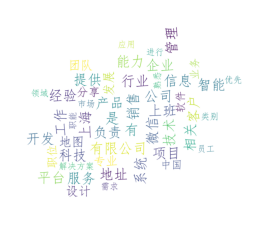

In [51]:
import matplotlib.pyplot as plt
from wordcloud import wordcloud

wc = wordcloud.WordCloud(
    font_path='Fangsong.ttf', 
    background_color='white',  
    width=1000,
    height=600,
    max_font_size=50,  #字体大小
    min_font_size=10,
    mask=plt.imread('back.jpg'),  # 背景图片
    max_words=1000
)

wc.generate(" ".join(content_text))
wc.to_file('jg.png')  # 图片保存

# 显示图片
plt.figure('jg')  
plt.imshow(wc)
plt.axis('off')  # 关闭坐标
plt.show()